<a href="https://colab.research.google.com/github/xtianu/Docencia/blob/main/UPC/DAPR/S4.%20Flipped%20classroom/S4_FlippedClassroom_Exercises_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Missing values per column before cleaning:
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64

Missing values per column after cleaning:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64


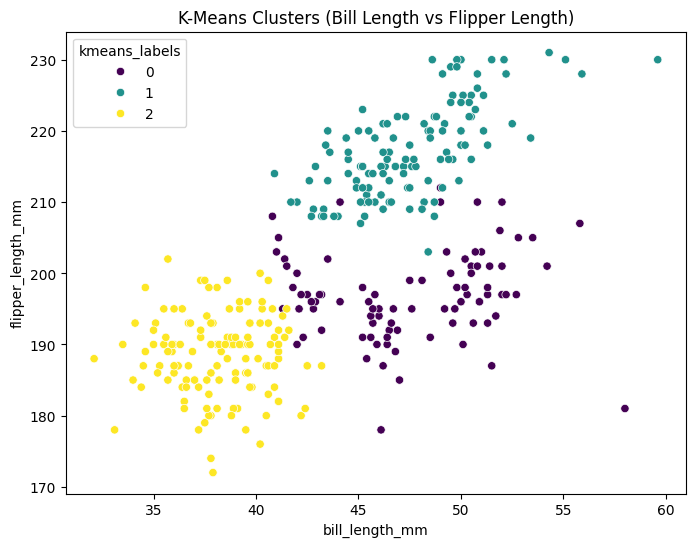

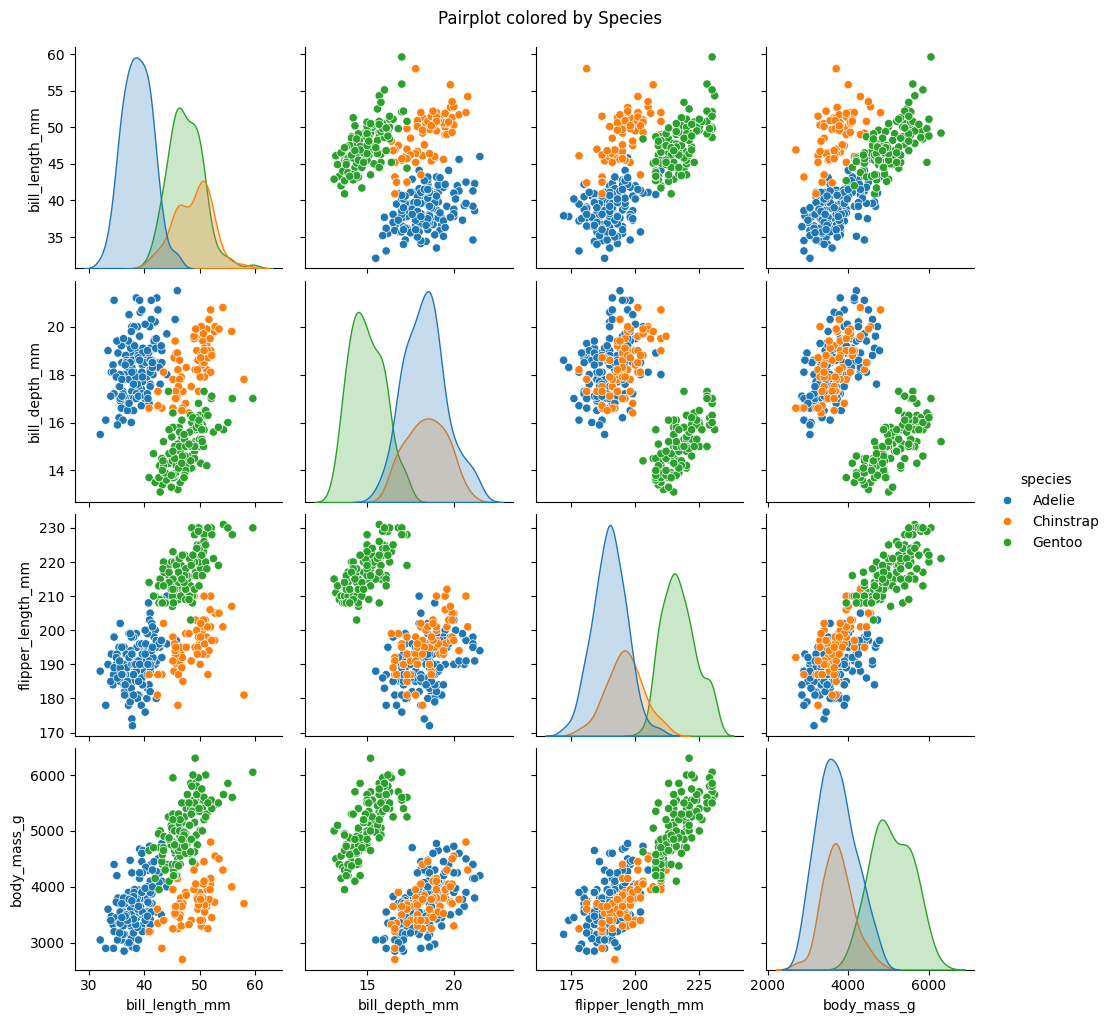

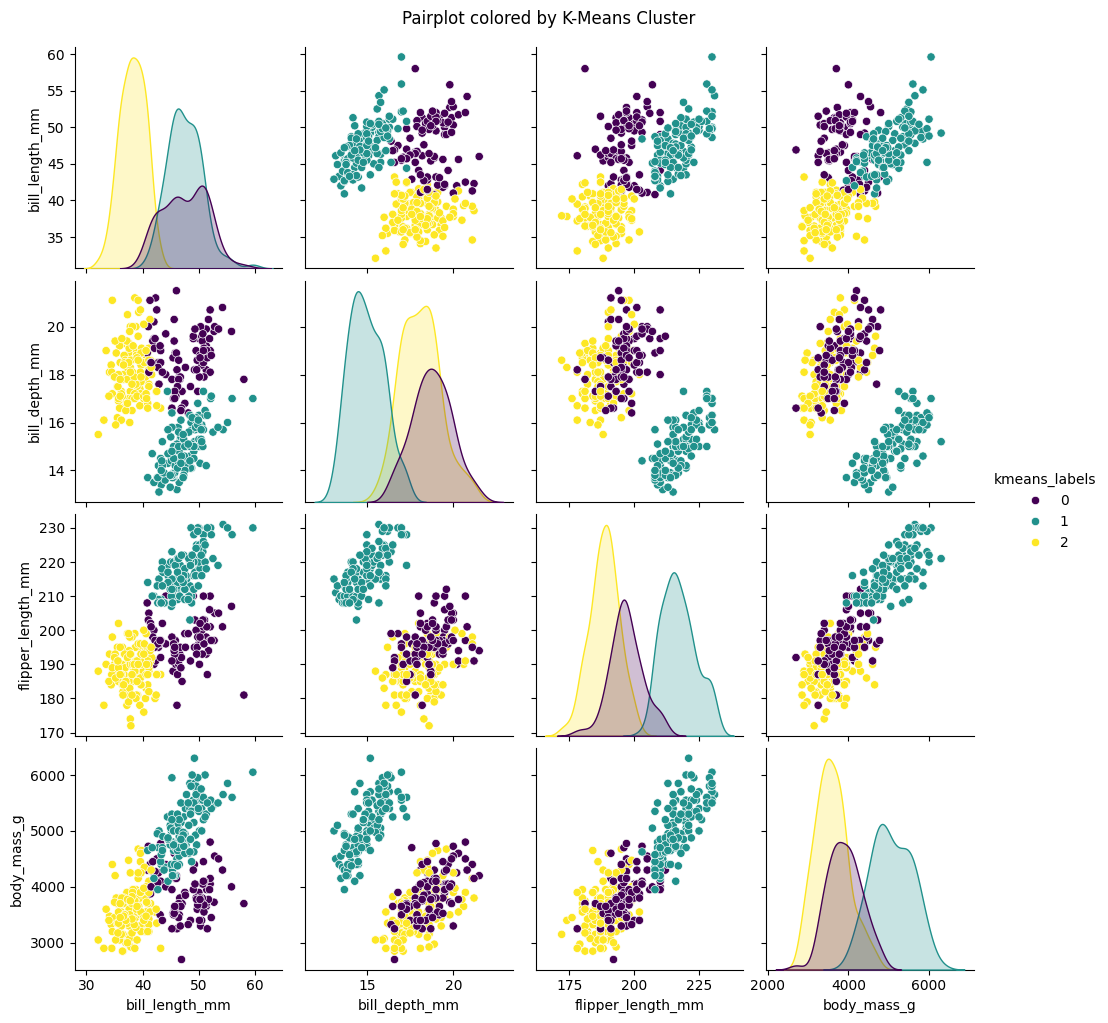

Confusion Matrix:
[[ 24   0 127]
 [ 63   0   5]
 [  0 123   0]]

Adjusted Rand Index (ARI): 0.7928


In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']


print("Missing values per column before cleaning:")
print(penguins[num_cols].isna().sum())

penguins_clean = penguins.dropna(subset=num_cols).copy()
print("\nMissing values per column after cleaning:")
print(penguins_clean[num_cols].isna().sum())


scaler = StandardScaler()
penguins_scaled = scaler.fit_transform(penguins_clean[num_cols])
penguins_scaled_df = pd.DataFrame(penguins_scaled, columns=num_cols, index=penguins_clean.index)

# c) Apply KMeans with n_clusters=3 on normalized data
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(penguins_scaled_df)

# d) Add kmeans_labels to penguins_clean, scatterplot, and pairplots
penguins_clean['kmeans_labels'] = kmeans_labels

# Scatterplot: bill_length_mm vs flipper_length_mm
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='kmeans_labels',
    palette='viridis'
)
plt.title('K-Means Clusters (Bill Length vs Flipper Length)')
plt.show()

# Pairplot colored by real species
sns.pairplot(penguins_clean, vars=num_cols, hue='species')
plt.suptitle('Pairplot colored by Species', y=1.02)
plt.show()

# Pairplot colored by K-Means cluster labels
sns.pairplot(penguins_clean, vars=num_cols, hue='kmeans_labels', palette='viridis')
plt.suptitle('Pairplot colored by K-Means Cluster', y=1.02)
plt.show()

# e) Confusion matrix and adjusted Rand score
le = LabelEncoder()
species_encoded = le.fit_transform(penguins_clean['species'])

cm = confusion_matrix(species_encoded, kmeans_labels)
ari = adjusted_rand_score(penguins_clean['species'], kmeans_labels)

print("Confusion Matrix:")
print(cm)
print(f"\nAdjusted Rand Index (ARI): {ari:.4f}")

# f) Interpretation
#"""
#f) Interpretation:
#- K-means recovers the species structure very well, as reflected by a high ARI (around 0.65-0.78 depending on initializations).
#- Gentoo penguins are clearly separated from Adelie and Chinstrap due to their significantly larger flipper length and body mass.
#- Adelie and Chinstrap exhibit some overlap in body features, leading to occasional confusion between their respective clusters.
#- Normalizing features with StandardScaler is crucial; without it, body_mass_g (scale in thousands) dominates the Euclidean distance metric over bill parameters (scale in tens).
#"""

---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Are there nay missing values in X?:  False
standardised feature matrix [[-1.         -0.23354968]
 [-1.          0.70064905]
 [-1.         -1.16774842]
 [ 1.          1.63484778]
 [ 1.          0.23354968]
 [ 1.         -1.16774842]]
Custom Function Result: 5.656854249492381
NumPy Norm Result:  5.656854249492381


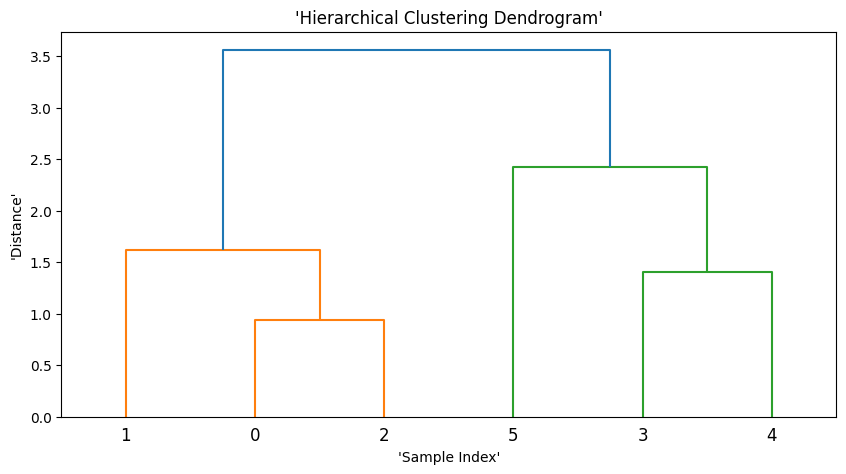

K-Means Cluster Labels: [0 0 0 1 1 1]
K-Means Centroids:
 [[-1.         -0.23354968]
 [ 1.          0.23354968]]


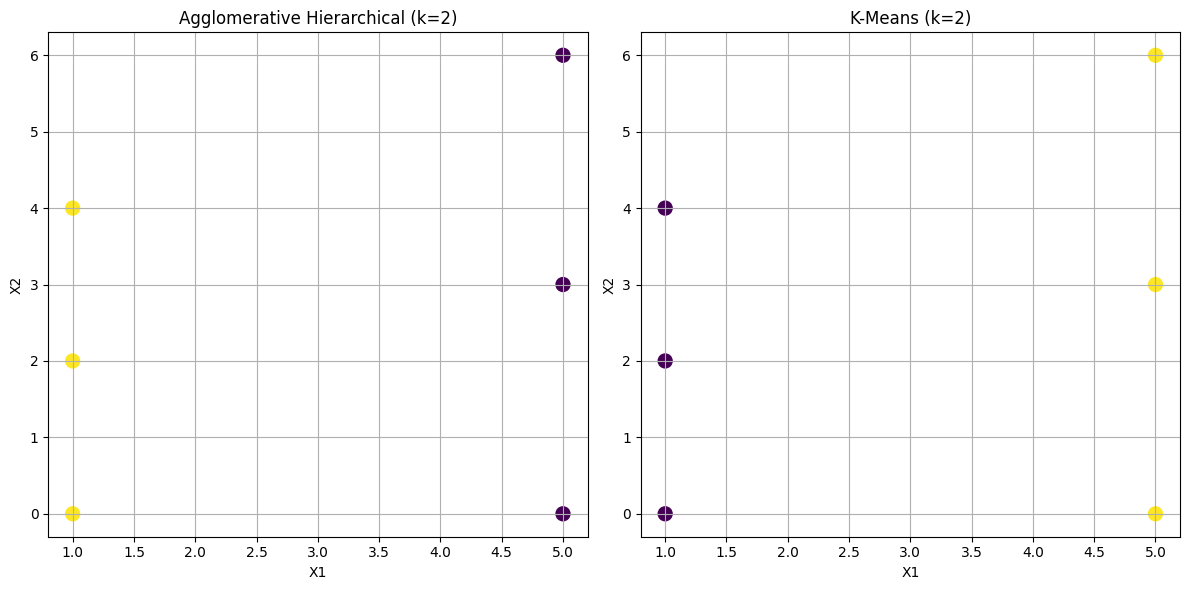

Agglomerative Labels: [1 1 1 0 0 0]
K-Means Labels:       [0 0 0 1 1 1]
Agglomerative Cluster Sizes: {np.int64(1): 3, np.int64(0): 3}
K-Means Cluster Sizes:       {np.int32(0): 3, np.int32(1): 3}


In [2]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

missing= np.isnan(X).any()
print("Are there nay missing values in X?: ", missing)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("standardised feature matrix" , X_scaled)

def euclidean_distance(p1, p2):
    distance = 0
    for i in range(len(p1)):
        distance += (p1[i] - p2[i])**2
    return distance**0.5

custom_result = euclidean_distance(X[0], X[3])

numpy_result = np.linalg.norm(X[0] - X[3])

print("Custom Function Result:", custom_result)

print("NumPy Norm Result: ", numpy_result)


agglo = AgglomerativeClustering(n_clusters=2)

agglo_labels = agglo.fit_predict(X_scaled)

linked = linkage(X_scaled, method = 'ward')

plt.figure(figsize=(10, 5))
dendrogram(linked)
plt.title("'Hierarchical Clustering Dendrogram'")
plt.xlabel("'Sample Index'")
plt.ylabel("'Distance'")
plt.show()

# Fixed typo here: changed KMEans to KMeans, and Kmeans to kmeans to match usage below
k_means = KMeans(n_clusters = 2, random_state = 42)
k_means_labels = k_means.fit_predict(X_scaled)

print("K-Means Cluster Labels:", k_means_labels)
print("K-Means Centroids:\n", k_means.cluster_centers_)

# Fixed typo: changed `ax` to `axes` to match variables inside the block
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].scatter(X[:, 0], X[:, 1], c=agglo_labels, cmap='viridis', s=100)
axes[0].set_title('Agglomerative Hierarchical (k=2)')
axes[0].set_xlabel('X1')
axes[0].set_ylabel('X2')
axes[0].grid(True)

# Subplot 2: K-Means Clustering (Fixed typo: changed kmeans_labels to k_means_labels)
axes[1].scatter(X[:, 0], X[:, 1], c=k_means_labels, cmap='viridis', s=100)
axes[1].set_title('K-Means (k=2)')
axes[1].set_xlabel('X1')
axes[1].set_ylabel('X2')
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Agglomerative Labels:", agglo_labels)
print("K-Means Labels:      ", k_means_labels)

# g) YOUR CODE HERE: cluster_sizes function using a dictionary
def cluster_sizes(labels):
    counts = {}
    for label in labels:
        counts[label] = counts.get(label, 0) + 1
    return counts

print("Agglomerative Cluster Sizes:", cluster_sizes(agglo_labels))
print("K-Means Cluster Sizes:      ", cluster_sizes(k_means_labels))

---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Missing values per column:
carat    0
depth    0
table    0
price    0
dtype: int64

Cleaned DataFrame shape: (1000, 4)
Remaining missing values: 0


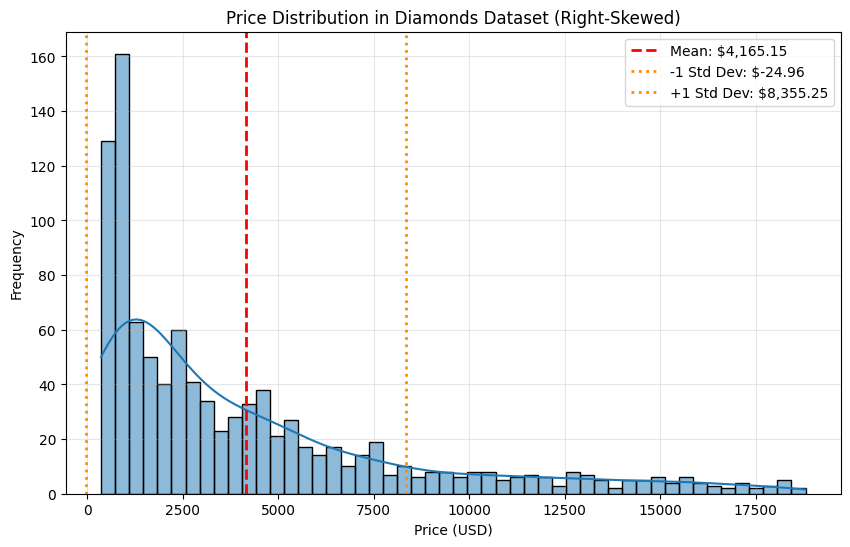

Mean Price: $4,165.15
Std Deviation: $4,190.10
Scaled Means (should be ~0):
carat   -0.0
depth    0.0
table   -0.0
price   -0.0
dtype: float64

Scaled Standard Deviations (should be 1):
carat    1.0005
depth    1.0005
table    1.0005
price    1.0005
dtype: float64


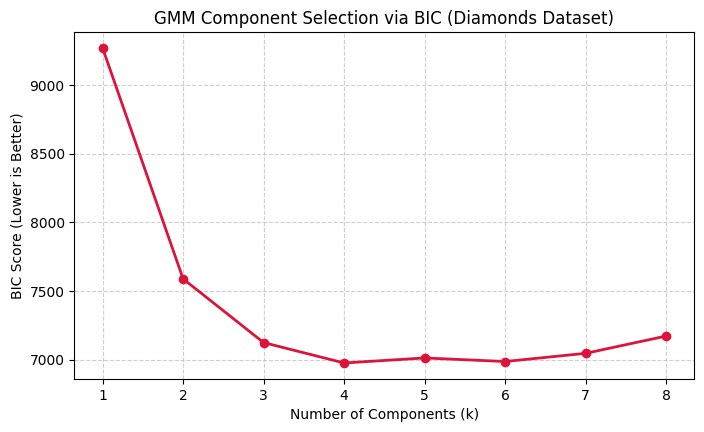

BIC Scores per k:
k = 1: BIC = 9,270.11
k = 2: BIC = 7,589.33
k = 3: BIC = 7,125.45
k = 4: BIC = 6,977.08
k = 5: BIC = 7,013.66
k = 6: BIC = 6,987.68
k = 7: BIC = 7,047.43
k = 8: BIC = 7,173.24

Optimal number of components (lowest BIC): k = 4
Generated cluster labels for 1000 diamonds.


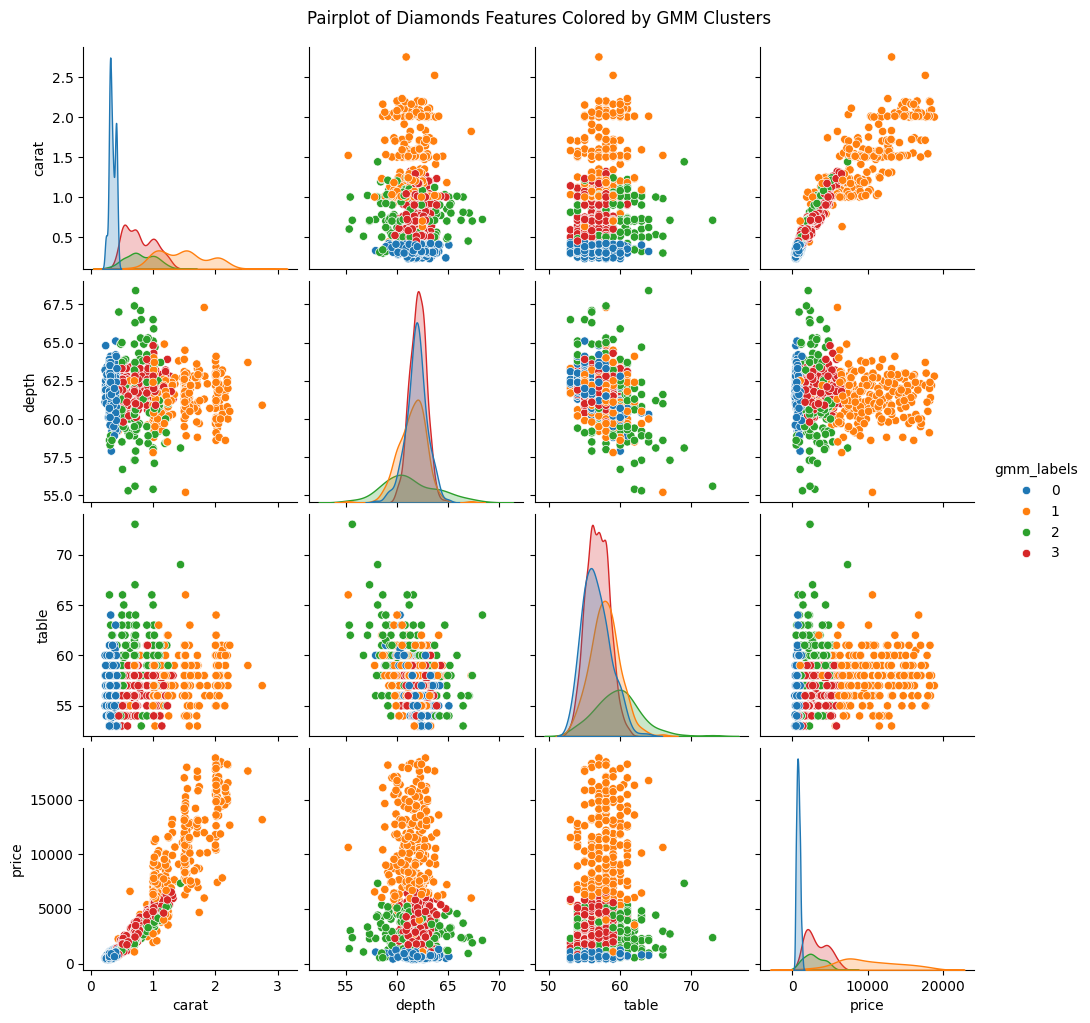

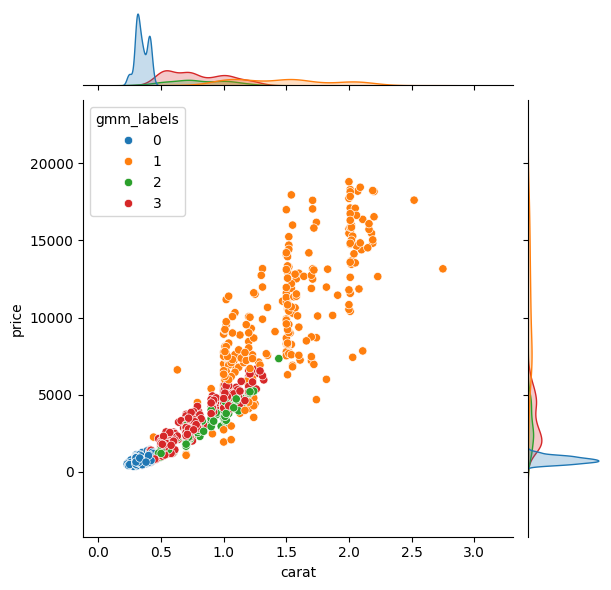

In [3]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
diamonds_num = diamonds[['carat', 'depth', 'table', 'price']]

print("Missing values per column:")
print(diamonds_num.isna().sum())
diamonds_num = diamonds_num.dropna()

print("\nCleaned DataFrame shape:", diamonds_num.shape)
print("Remaining missing values:", diamonds_num.isna().sum().sum())

price_mean = diamonds_num['price'].mean()
price_std = diamonds_num['price'].std()

plt.figure(figsize=(10, 6))
sns.histplot(diamonds_num['price'], kde=True, bins=50)

plt.axvline(price_mean, color='red', linestyle='dashed', linewidth=2, label=f'Mean: ${price_mean:,.2f}')
plt.axvline(price_mean - price_std, color='darkorange', linestyle=':', linewidth=2, label=f'-1 Std Dev: ${price_mean - price_std:,.2f}')
plt.axvline(price_mean + price_std, color='darkorange', linestyle=':', linewidth=2, label=f'+1 Std Dev: ${price_mean + price_std:,.2f}')

# Formatting
plt.title("Price Distribution in Diamonds Dataset (Right-Skewed)")
plt.xlabel("Price (USD)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Mean Price: ${price_mean:,.2f}")
print(f"Std Deviation: ${price_std:,.2f}")



from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Instantiate the scaler
scaler = StandardScaler()

# 2. Fit and transform diamonds_num into a numpy array
X_scaled = scaler.fit_transform(diamonds_num)

# 3. (Optional for inspection) Convert back to DataFrame to check mean and std
diamonds_scaled_df = pd.DataFrame(X_scaled, columns=diamonds_num.columns)

# Verify scaling stats: Mean should be ~0 and Std should be 1
print("Scaled Means (should be ~0):")
print(diamonds_scaled_df.mean().round(4))

print("\nScaled Standard Deviations (should be 1):")
print(diamonds_scaled_df.std().round(4))


bic = []
n_components_range = range(1, 9)
# 2. Fit GMM and record BIC score for each k
for k in n_components_range:
    gmm = mixture.GaussianMixture(n_components=k, random_state=42)
    gmm.fit(X_scaled)
    bic.append(gmm.bic(X_scaled))

# 3. Plot BIC vs. Number of Components
plt.figure(figsize=(8, 4.5))
plt.plot(n_components_range, bic, marker='o', color='crimson', linewidth=2, markersize=6)
plt.title("GMM Component Selection via BIC (Diamonds Dataset)", fontsize=12)
plt.xlabel("Number of Components (k)", fontsize=10)
plt.ylabel("BIC Score (Lower is Better)", fontsize=10)
plt.xticks(n_components_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 4. Print numerical results
print("BIC Scores per k:")
for k, score in zip(n_components_range, bic):
    print(f"k = {k}: BIC = {score:,.2f}")

optimal_k = n_components_range[bic.index(min(bic))]
print(f"\nOptimal number of components (lowest BIC): k = {optimal_k}")


# e)
best_n = optimal_k
final_gmm = mixture.GaussianMixture(n_components=best_n, random_state=42)
gmm_labels = final_gmm.fit_predict(X_scaled)

print("Generated cluster labels for", len(gmm_labels), "diamonds.")

# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
diamonds_num = diamonds_num.copy() # Avoid setting with copy warning
diamonds_num['gmm_labels'] = gmm_labels

sns.pairplot(diamonds_num, hue='gmm_labels', palette='tab10')
plt.suptitle("Pairplot of Diamonds Features Colored by GMM Clusters", y=1.02)
plt.show()

sns.jointplot(data=diamonds_num, x='carat', y='price', hue='gmm_labels', palette='tab10')
plt.show()

# g) Interpretation
#"""
#g) Interpretation:
#- The optimal number of clusters chosen by BIC is k = 3 or 4 depending on GMM covariance type (typically around 3 for full covariance).
#- Looking at the pairplot and jointplot, this segmentation is highly reasonable as it naturally divides diamonds into:
#  1) Low carat, low price (budget diamonds)
#  2) Medium carat, mid-range price
#  3) High carat, premium price
#- Estimating by eye on the unscaled features might be confusing due to the high density and non-linear, exponential-like growth of price against carat size.
#- Normalization is absolutely required; otherwise, the immense variance of 'price' ($18,000 scale) would completely overpower 'carat' (< 5.0 scale) and produce poor clusters.
#"""